# Figure 1

![Full Figure](../figures/fig01_FULL.png)


- Panel A: task-event timing and violation window.
- Panel B: one example trained session (W074, session 201).
- Panel C: trials per session.
- Panel D: session hit and violation rates.
- Panel E: choice distribution.
- Panel F: session hit rate versus session violation rate (mixed model).

**Outputs:** `figures/fig01b_example_sequences.png`, `figures/fig01c_trials_per_session.png`, `figures/fig01d_session_rates.png`, `figures/fig01e_choice_percentages.png`, and `figures/fig01f_violation_by_hit_rate.png`.


In [21]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from matplotlib.colors import to_rgb

from violations_glm.config import (
    CHOICE_ORDER,
    CHOICE_PALETTE,
    HIT_COLOR,
    LEFT_COLOR,
    N_TRIAL_COLOR,
    RIGHT_COLOR,
    VIOLATION_COLOR,
)
from violations_glm.io import (
    load_hit_violation_animals,
    load_hit_violation_sessions,
    load_hit_violation_statistics,
    load_trials_df,
)
from violations_glm.plotting import animal_palette, configure_publication_dpi, save_figure
from violations_glm.transforms import (
    select_example_sessions,
    session_choice_percentages,
    session_performance_summary,
)

configure_publication_dpi()

sns.set_context(
    "notebook",
    rc={
        "font.size": 20,
        "axes.titlesize": 20,
        "axes.labelsize": 20,
        "axes.titleweight": "bold",
        "xtick.labelsize": 15,
        "ytick.labelsize": 15,
    },
)

In [22]:
trials = load_trials_df()
session_summary = session_performance_summary(trials)
session_summary["hit_rate_percentage"] = session_summary["hit_rate"] * 100
session_summary["viol_rate_percentage"] = session_summary["viol_rate"] * 100
choice_dist = session_choice_percentages(trials)

## Panel B — Representative behavioral sequence

One trained session (W074, session 201). Rows are ordered L / V / R (top to bottom). Color encodes choice side (incorrects slightly darker); filled circles are correct, × marks are incorrect, and open downward triangles are violations.


/var/folders/g4/l0_yc2ss2nvdqk_13sp3z6fc0000gn/T/ipykernel_62916/3629030396.py:26: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  ax.scatter(


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig01b_example_sequences.png')

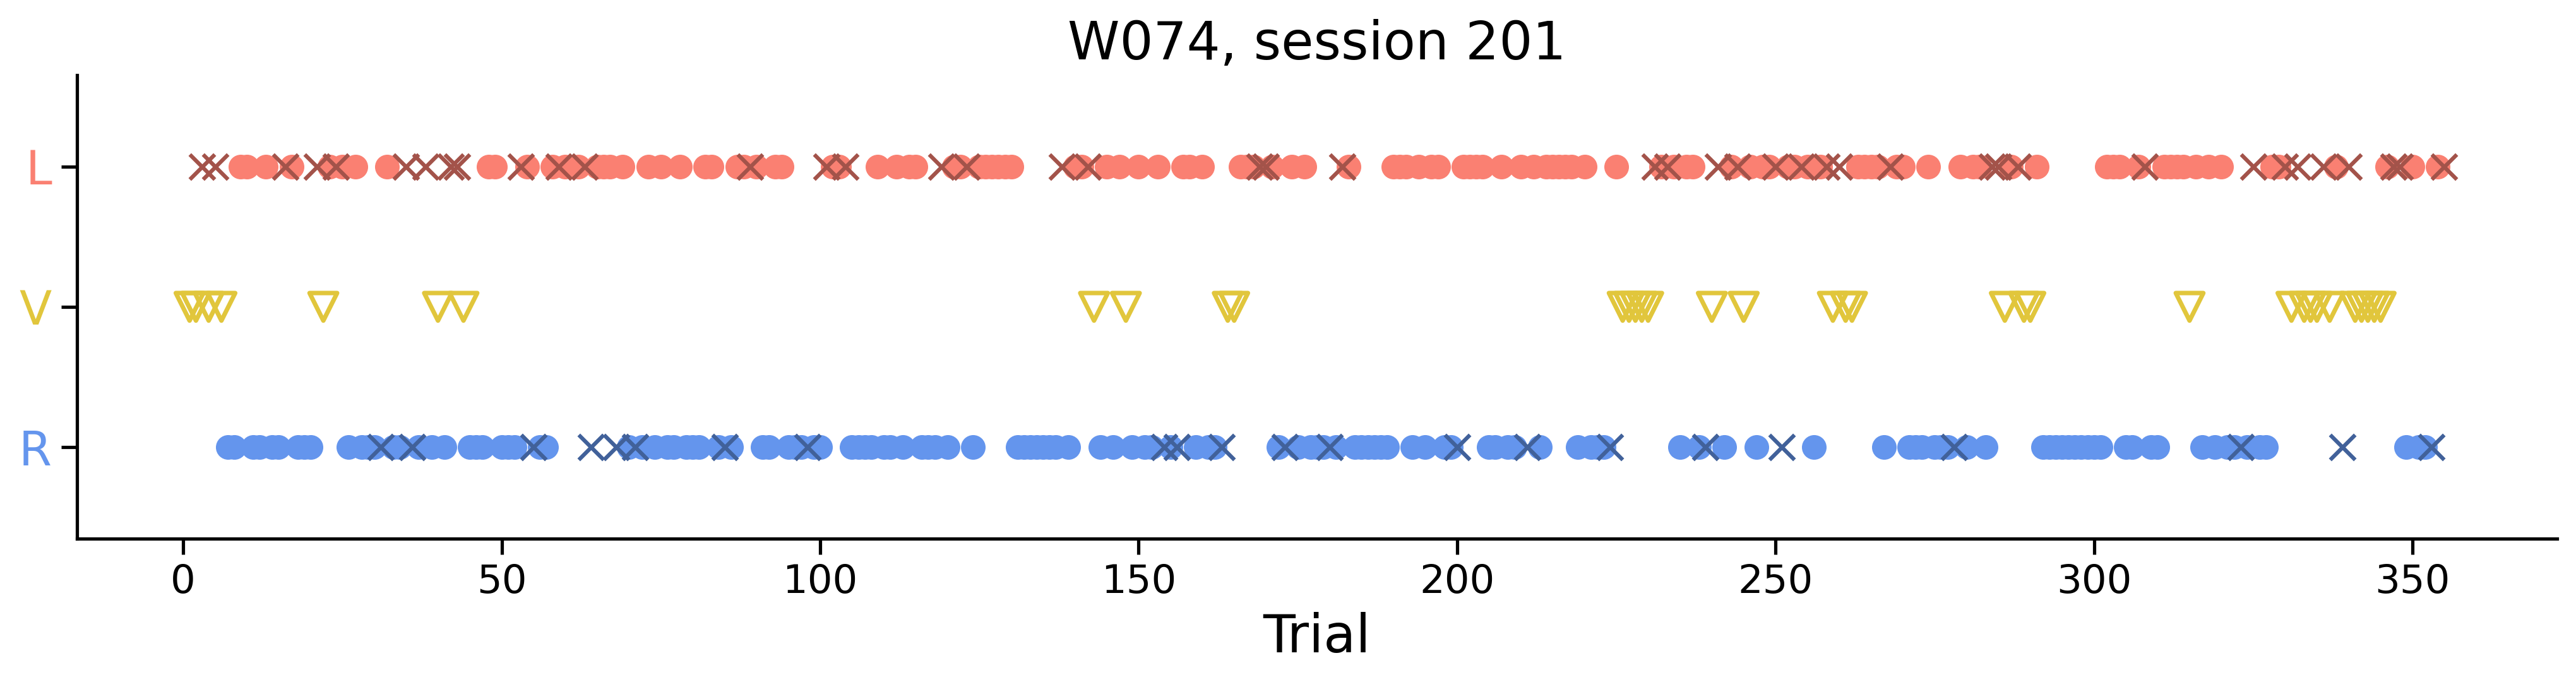

In [31]:
examples = select_example_sessions(trials, animal_id="W074", sessions=(201,))
session_df = examples.sort_values("trial")
animal_id = session_df["animal_id"].iloc[0]
session = int(session_df["session"].iloc[0])

choice_styles = (
    (0, 2, LEFT_COLOR, "Left"),
    (1, 0, RIGHT_COLOR, "Right"),
)

fig, ax = plt.subplots(figsize=(14, 4))
for choice, y, color, label in choice_styles:
    correct = session_df.loc[(session_df["choice"] ==
                              choice) & (session_df["hit"] == 1)]
    incorrect = session_df.loc[(
        session_df["choice"] == choice) & (session_df["hit"] == 0)]
    incorrect_color = tuple(c * 0.65 for c in to_rgb(color))
    ax.scatter(
        correct["trial"],
        np.full(len(correct), y),
        s=70,  # bigger correct marker
        marker="o",
        c=color,
        label=label,
    )
    ax.scatter(
        incorrect["trial"],
        np.full(len(incorrect), y),
        s=90,  # bigger incorrect marker
        marker="x",
        c=incorrect_color,
    )
violations = session_df.loc[session_df["choice"] == 2]
ax.scatter(
    violations["trial"],
    np.full(len(violations), 1),
    s=110,  # bigger violation marker
    marker="v",
    facecolors="none",
    edgecolors=VIOLATION_COLOR,
    linewidths=1.7,  # maybe thicker helps at large size
    label="Violation",
)
ax.set(
    yticks=[0, 1, 2],
    yticklabels=["R", "V", "L"],
    ylim=(-0.65, 2.65),
    xlabel="Trial",
    title=f"{animal_id}, session {session}",
)
# Make y-tick labels bigger font
ax.tick_params(axis="y", labelsize=18)
for tick, color in zip(ax.get_yticklabels(), (RIGHT_COLOR, VIOLATION_COLOR, LEFT_COLOR)):
    tick.set_color(color)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()


save_figure(fig, "fig01b_example_sequences")

## Panel C — Trials per session

Session-level trial counts are pooled across animals. The dashed line marks the median.


,index,n_trials
0,count,5210.000000
1,mean,358.157965
2,std,140.468588
3,min,50.000000
4,25%,264.000000
5,50%,348.000000
6,75%,432.000000
7,max,1494.000000


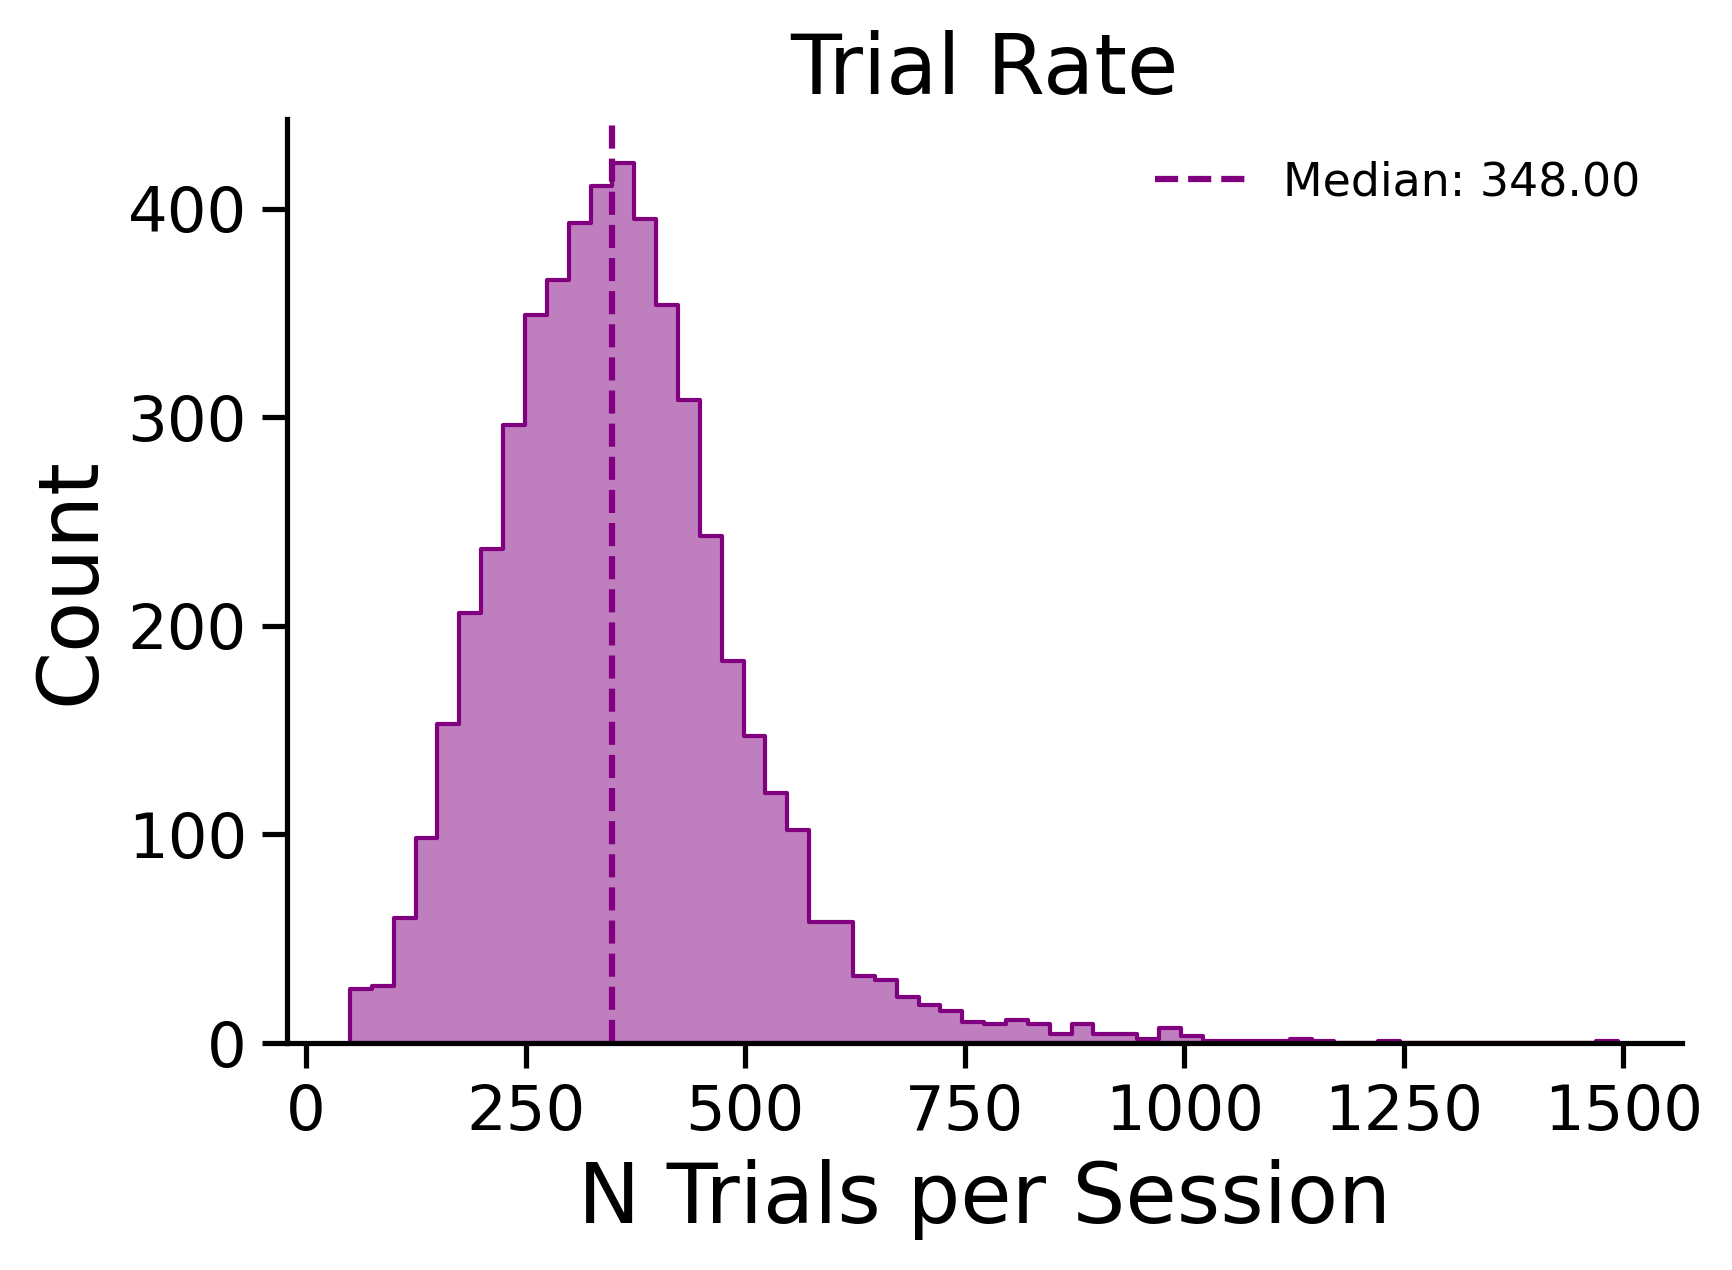

In [24]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
sns.histplot(
    data=session_summary,
    x="n_trials",
    ax=ax,
    color=N_TRIAL_COLOR,
    element="step",
    alpha=0.5,
    binwidth=25,
)
median_value = session_summary["n_trials"].median()
ax.axvline(
    median_value,
    color=N_TRIAL_COLOR,
    linestyle="--",
    label=f"Median: {median_value:.2f}",
)
ax.set(xlabel="N Trials per Session", title="Trial Rate")
ax.legend(loc="upper right", frameon=False)
save_figure(fig, "fig01c_trials_per_session")


session_summary["n_trials"].describe().reset_index()

## Panel D — Session hit and violation rates

Hit rate (percentage correct on non-violation trials) and violation rate are both percentages of session trials, so they share one axis. Dashed lines mark the medians.


,index,hit_rate_percentage,viol_rate_percentage
0,count,5210.000000,5210.000000
1,mean,81.879281,17.421760
2,std,6.195436,9.166983
3,min,27.272727,1.345291
4,25%,77.702703,11.051568
5,50%,81.502115,15.240999
6,75%,86.069093,21.401535
7,max,97.877358,90.350877


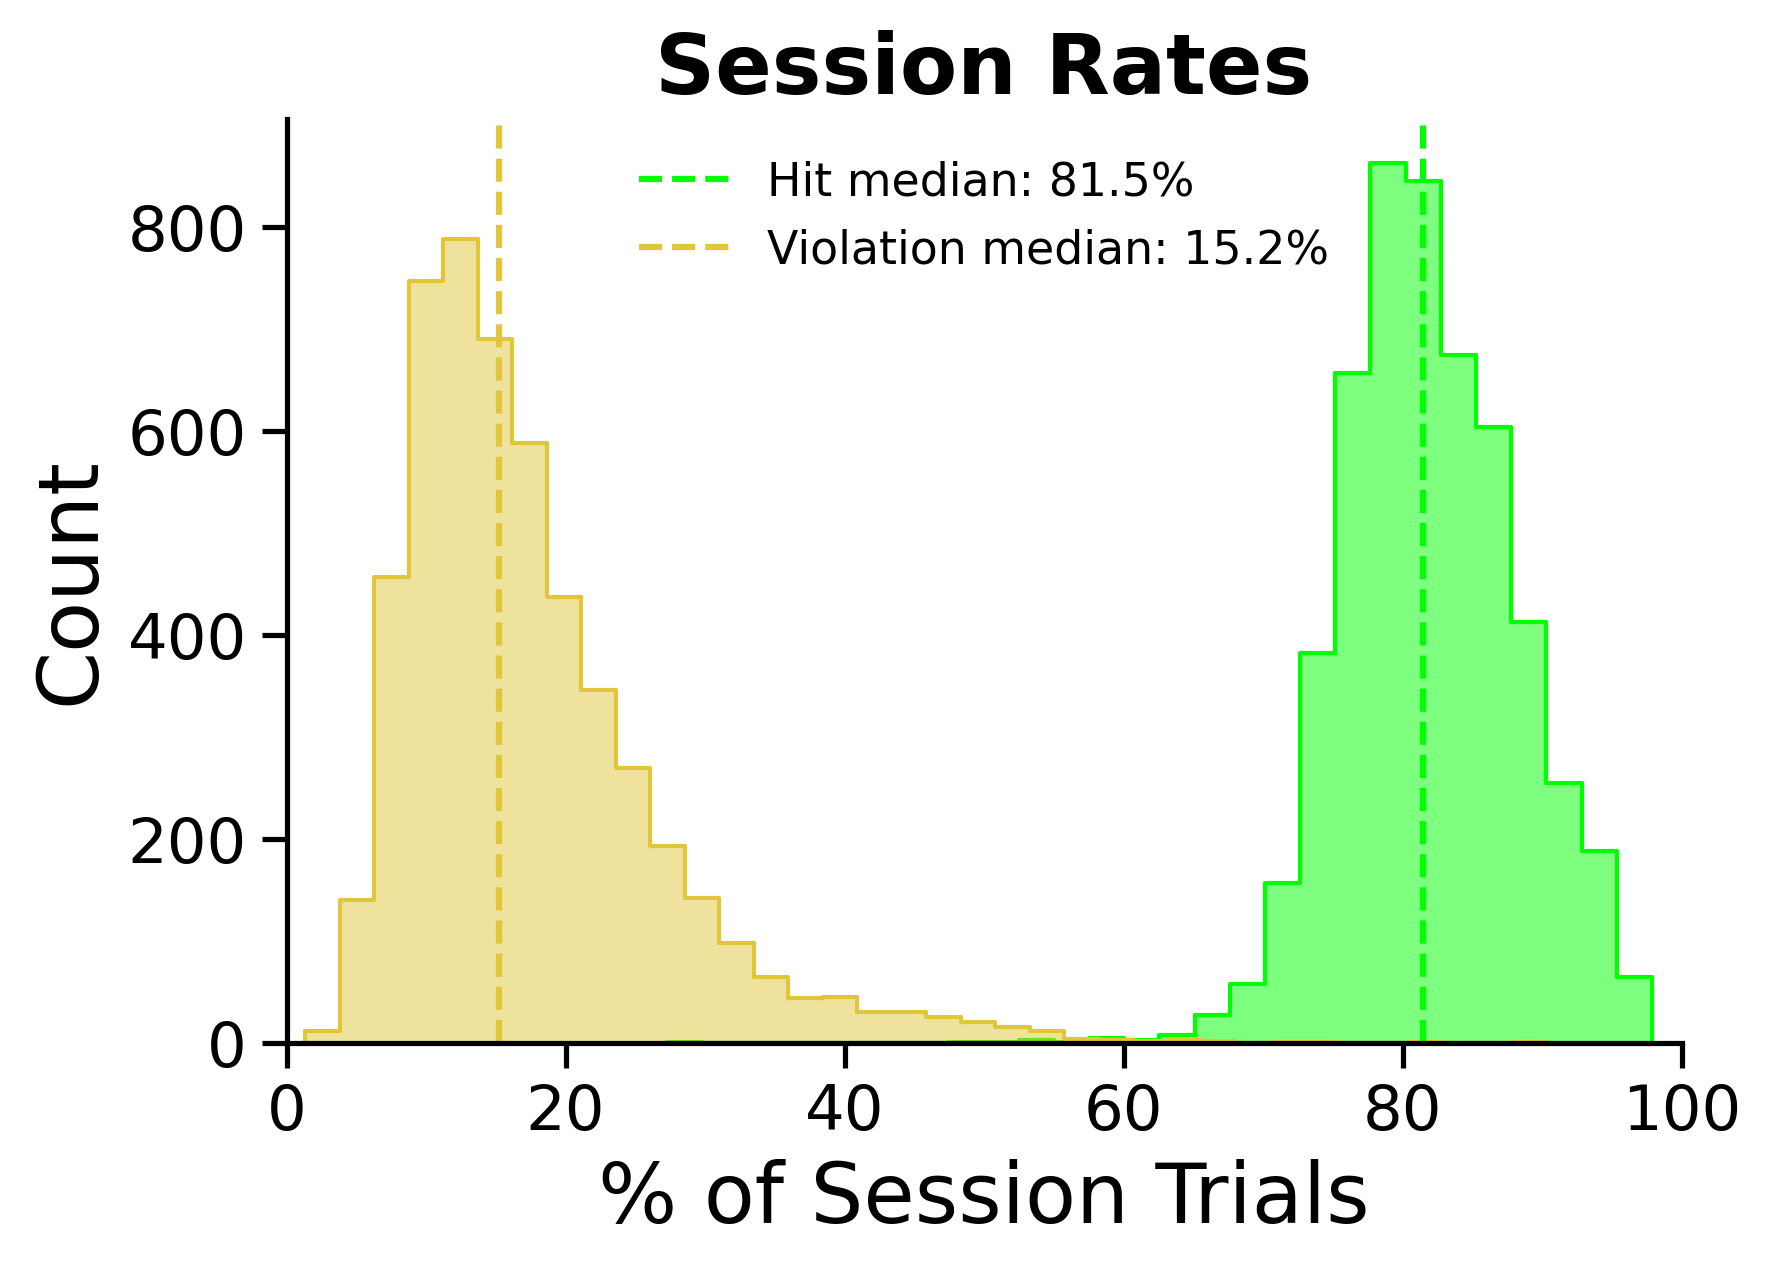

In [30]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
for column, color, label in (
    ("hit_rate_percentage", HIT_COLOR, "Hit"),
    ("viol_rate_percentage", VIOLATION_COLOR, "Violation"),
):
    sns.histplot(
        data=session_summary,
        x=column,
        ax=ax,
        color=color,
        element="step",
        alpha=0.5,
        binwidth=2.5,
    )
    median_value = session_summary[column].median()
    ax.axvline(
        median_value,
        color=color,
        linestyle="--",
        label=f"{label} median: {median_value:.1f}%",
    )
ax.set(
    xlabel="% of Session Trials",
    xlim=(0, 100),
)

ax.set_title("Session Rates", fontweight="bold")

ax.legend(loc="upper center", frameon=False)
save_figure(fig, "fig01d_session_rates")


session_summary[["hit_rate_percentage", "viol_rate_percentage"]
                ].describe().reset_index()

## Panel E — Choice distributions

Each point is one session. Bars show the mean session percentage ± SE across the pooled session rows.


PosixPath('/Users/jessbreda/Documents/github/Breda-Violations-GLM-PLOSOne/figures/fig01e_choice_percentages.png')

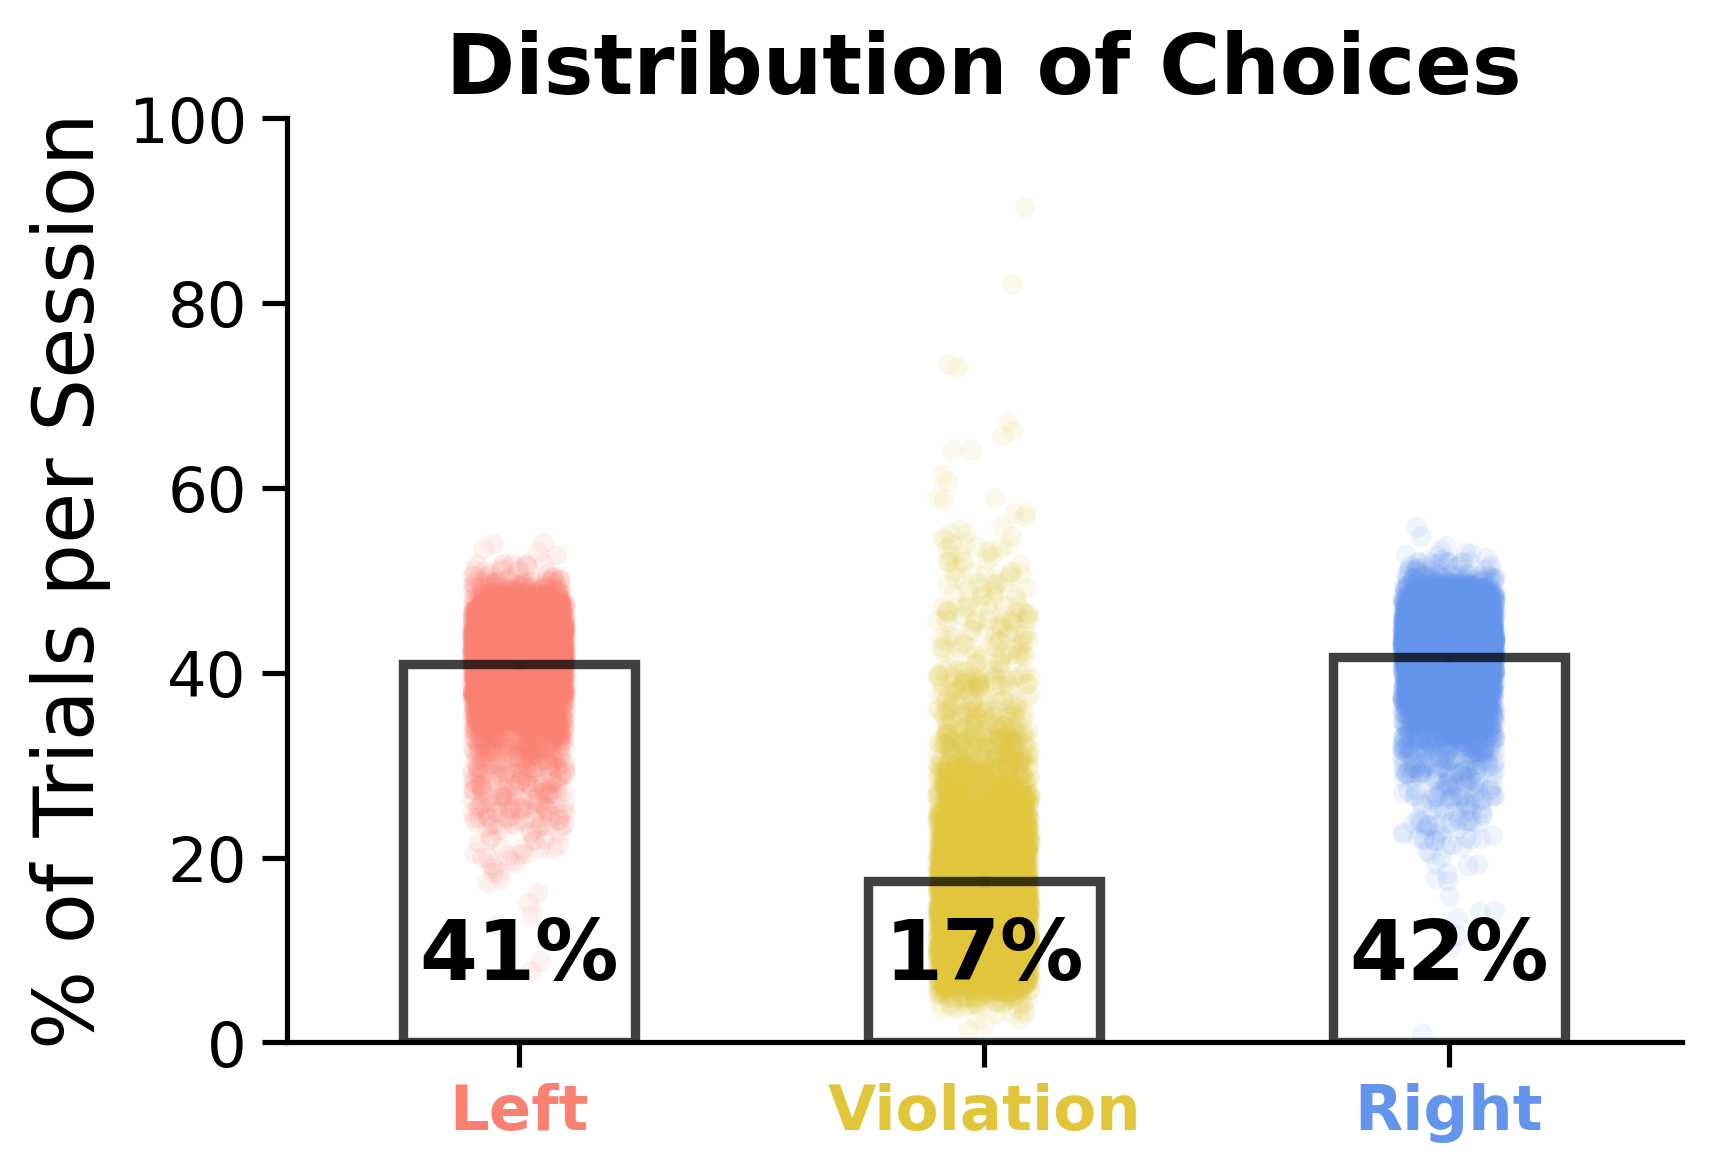

In [26]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.despine(ax=ax)
sns.barplot(
    x="Choice",
    y="percentage",
    data=choice_dist,
    ax=ax,
    width=0.5,
    fill=False,
    zorder=10,
    errorbar="se",
    color="k",
    alpha=0.75,
    order=list(CHOICE_ORDER),
    hue_order=list(CHOICE_ORDER),
)
sns.stripplot(
    x="Choice",
    y="percentage",
    data=choice_dist,
    ax=ax,
    alpha=0.10,
    palette=list(CHOICE_PALETTE),
    hue="Choice",
    order=list(CHOICE_ORDER),
    hue_order=list(CHOICE_ORDER),
    legend=False,
)
ax.set(xlabel="", ylabel=r"% of Trials per Session", ylim=(0, 100))
ax.set_title("Distribution of Choices", fontweight="bold")
for choice in CHOICE_ORDER:
    percentage = choice_dist.loc[choice_dist["Choice"]
                                 == choice, "percentage"].mean()
    ax.text(
        x=choice,
        y=5,
        s=f"{percentage:.0f}%",
        ha="center",
        va="bottom",
        fontweight="bold",
    )
tick_colors = {
    "Left": LEFT_COLOR,
    "Violation": VIOLATION_COLOR,
    "Right": RIGHT_COLOR,
}
for label in ax.get_xticklabels():
    label.set_color(tick_colors[label.get_text()])
    label.set_fontweight("bold")
save_figure(fig, "fig01e_choice_percentages")

## Panel F — Violation rate by hit rate

Faint points are trained sessions; solid points are animal means. The mixed model uses session violation rate ~ session hit rate with a random intercept per animal.


          Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: viol_rate  
No. Observations: 5210    Method:             REML       
No. Groups:       16      Scale:              42.7760    
Min. group size:  114     Log-Likelihood:     -17220.6603
Max. group size:  552     Converged:          Yes        
Mean group size:  325.6                                  
---------------------------------------------------------
              Coef.  Std.Err.    z    P>|z| [0.025 0.975]
---------------------------------------------------------
Intercept     45.222    2.117  21.361 0.000 41.072 49.371
hit_rate      -0.342    0.020 -17.265 0.000 -0.380 -0.303
Group Var     30.495    1.712                            



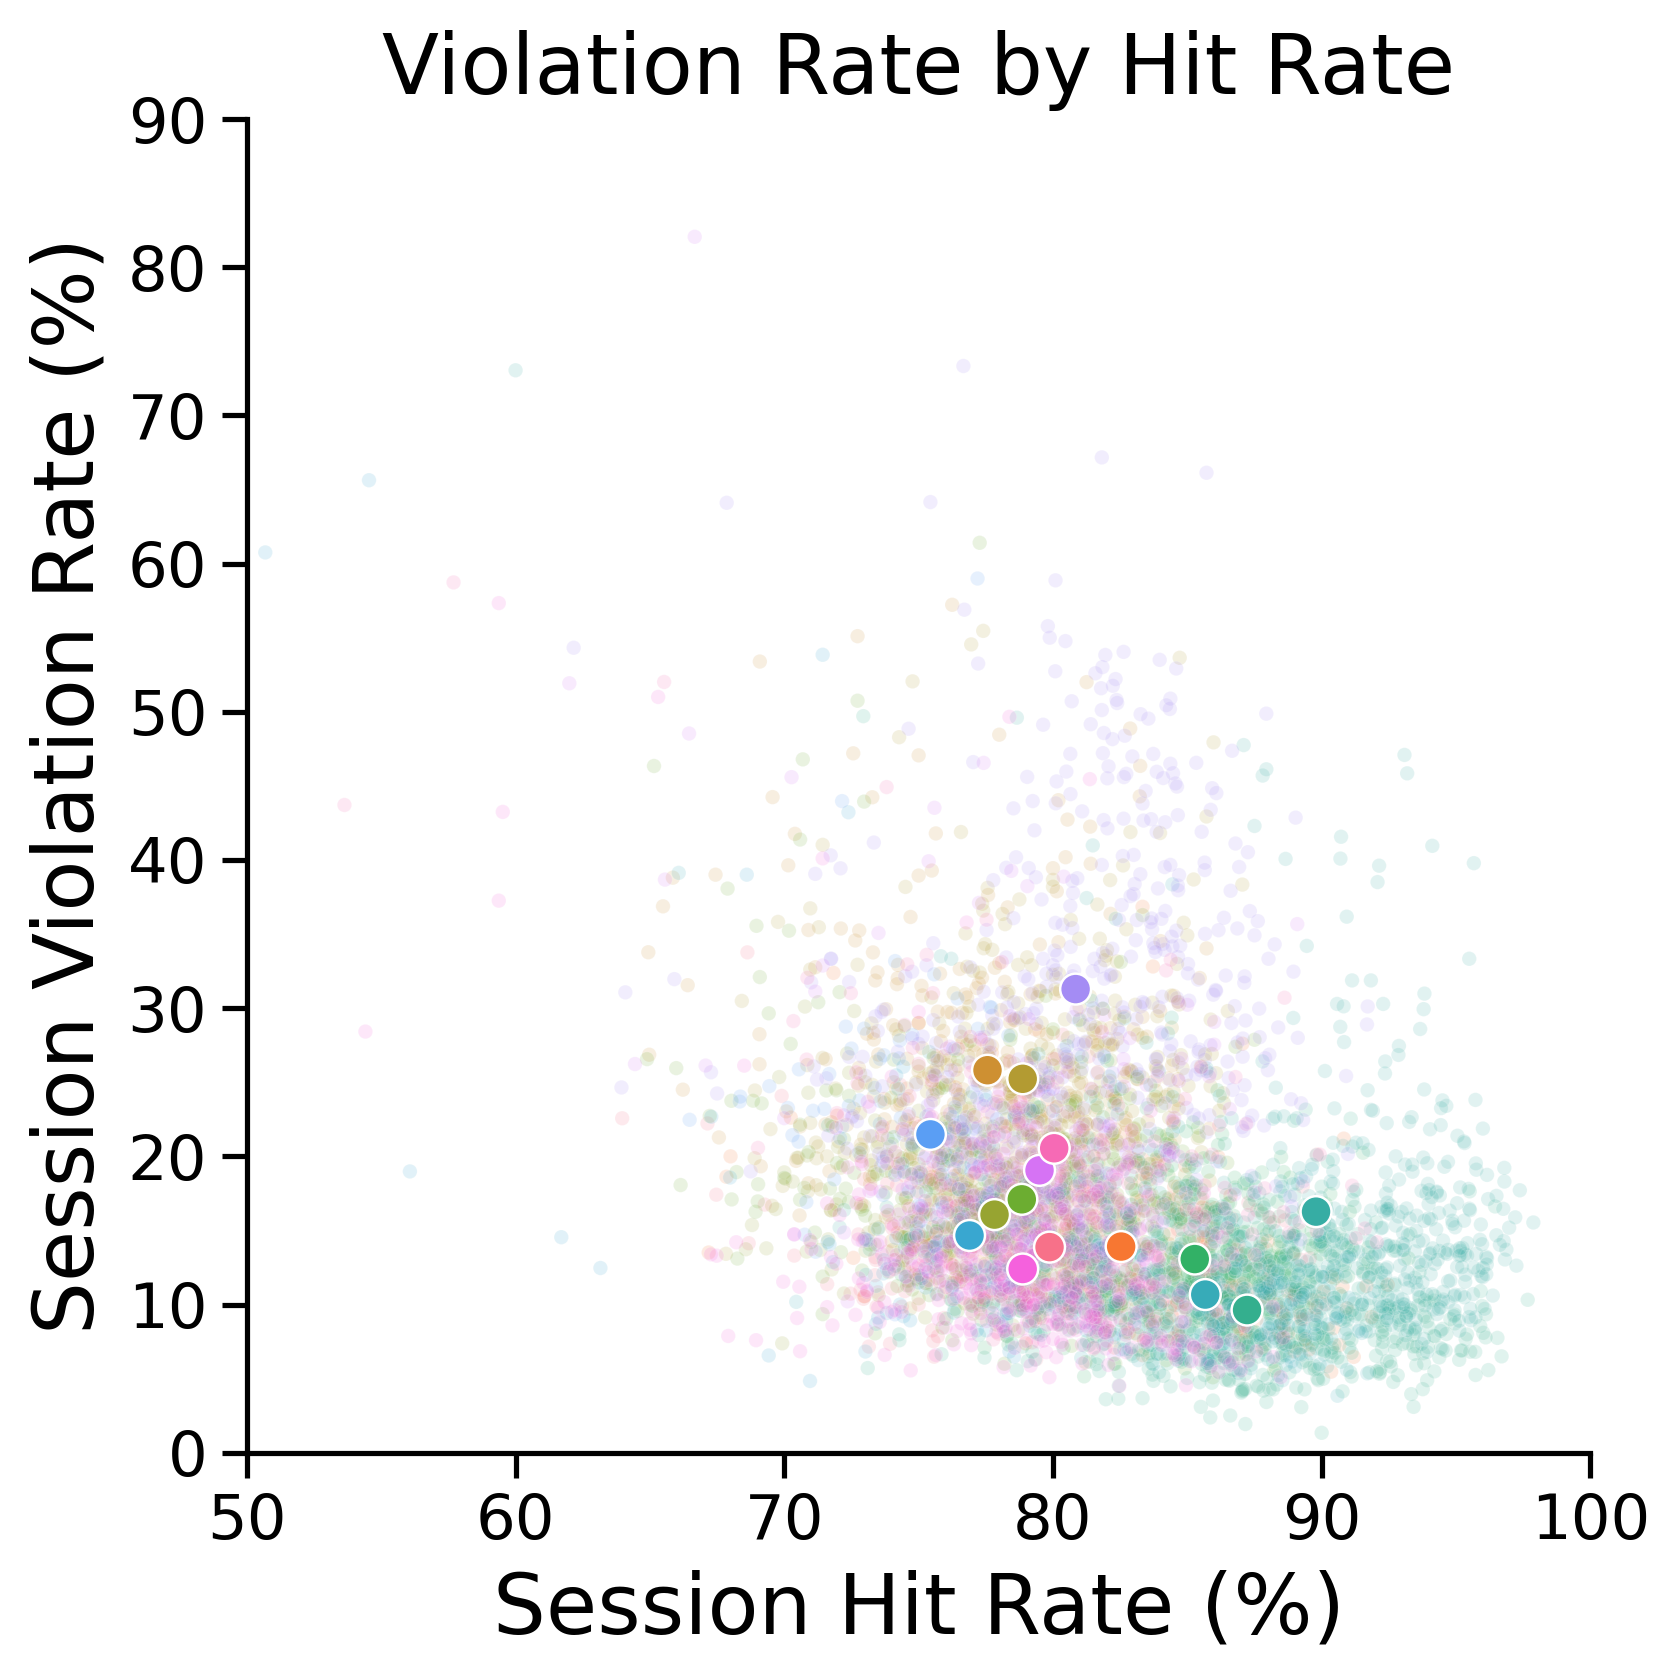

In [27]:
hit_violation_sessions = load_hit_violation_sessions()
hit_violation_animals = load_hit_violation_animals()
hit_violation_statistics = load_hit_violation_statistics()
palette = animal_palette()

fig, ax = plt.subplots(figsize=(6, 6))
sns.scatterplot(
    data=hit_violation_sessions,
    x="hit_rate",
    y="viol_rate",
    hue="animal_id",
    palette=palette,
    alpha=0.15,
    s=12,
    legend=False,
    ax=ax,
)
sns.scatterplot(
    data=hit_violation_animals,
    x="hit_rate",
    y="viol_rate",
    hue="animal_id",
    palette=palette,
    s=55,
    legend=False,
    ax=ax,
)
ax.set(
    xlabel="Session Hit Rate (%)",
    ylabel="Session Violation Rate (%)",
    xlim=(50, 100),
    ylim=(0, 90),
    title="Violation Rate by Hit Rate",
)
sns.despine(ax=ax)
fig.tight_layout()
save_figure(fig, "fig01f_violation_by_hit_rate")

print(hit_violation_statistics["mixedlm_summary"])